## CMPSC 105 Lab 07: Interpreting Hypothesis Tests

Your name(s): Will Gruca Jose Cifuentes

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# 1. DATA GENERATION (Run this cell to load your "lab_data")

# Generate doomscolling data
n_users = 1000

user_baselines = np.random.gamma(shape=3.0, scale=40.0, size=n_users)
standard_time = user_baselines + np.random.normal(loc=0, scale=10, size=n_users)
new_time = user_baselines + np.random.normal(loc=1.5, scale=10, size=n_users)
df_doomscrolling = pd.DataFrame({
    'user_id': np.arange(n_users),
    'standard_time': standard_time,
    'new_time': new_time
})
df_doomscrolling['difference'] = df_doomscrolling['new_time'] - df_doomscrolling['standard_time']
df_doomscrolling = df_doomscrolling.sample(frac=1, ignore_index=True)
    

# Generate e-commerce A/B test Data
blue_spending = np.random.normal(loc=42.50, scale=25.0, size=2000)
green_spending = np.random.normal(loc=43.10, scale=25.0, size=2000)
blue_spending = np.clip(blue_spending, a_min=0, a_max=None)
green_spending = np.clip(green_spending, a_min=0, a_max=None)

df_ecommerce = pd.DataFrame({
    'button_color': ['Blue'] * 2000 + ['Green'] * 2000,
    'spending': np.concatenate([blue_spending, green_spending])
})
df_ecommerce = df_ecommerce.sample(frac=1, ignore_index=True)

print("Datasets generated successfully!")


Datasets generated successfully!


### Scenario 1: The E-Commerce A/B Test

An e-commerce company is conducting an **A/B test** to determine the effect of button color on user spending for their shopping app. An A/B test is a controlled experiment where two or more variants of a single variable are compared to determine which performs better. In this case, the variable is the button color, and the outcome is user spending. 

Users are randomly assigned to see either a blue or green button, and their spending is recorded. The goal is to assess whether the button color influences the amount users spend.

In [3]:
df_ecommerce.head()

,button_color,spending
0,Blue,10.327157
1,Blue,62.293486
2,Blue,78.623108
3,Green,45.964878
4,Green,71.219604


In [4]:
# Calculate the observed difference in means
ecomm_means = df_ecommerce.groupby('button_color')['spending'].mean()
obs_diff_ecomm = ecomm_means['Green'] - ecomm_means['Blue']

print(f"Blue Button Mean: ${ecomm_means['Blue']:.2f}")
print(f"Green Button Mean: ${ecomm_means['Green']:.2f}")
print(f"Observed Difference: ${obs_diff_ecomm:.2f}")


Blue Button Mean: $43.11
Green Button Mean: $43.17
Observed Difference: $0.06


We can test whether the differenece between the green and blue button spending is statistically significant using a permutation test, where we repeatedly shuffle the button color labels and calculate the difference in mean spending between the green and blue buttons. This generates a null distribution of differences, which we can then compare to the observed difference to compute a p-value.

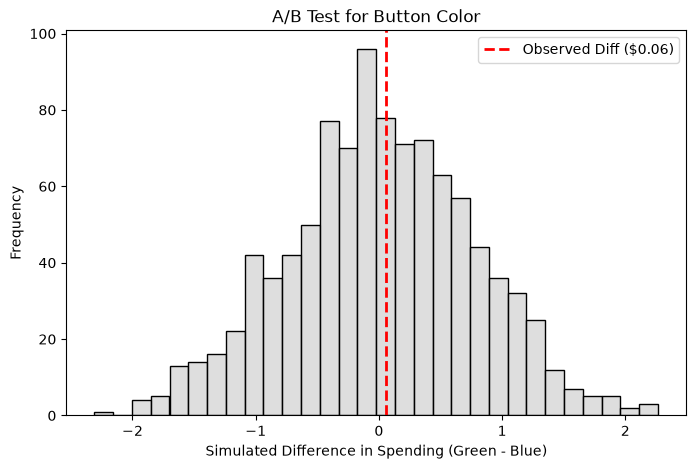

P-value for A/B Test (Button Color): 0.5330


In [5]:
# Permutation test
n_iter = 1000
simulated_diffs_ecomm = np.zeros(n_iter)

spending_vals = df_ecommerce['spending'].values
color_labels = df_ecommerce['button_color'].values

for i in range(n_iter):
    # Shuffle the labels
    shuffled = np.random.permutation(color_labels)
    
    # Calculate simulated means
    green_mean = spending_vals[shuffled == 'Green'].mean()
    blue_mean = spending_vals[shuffled == 'Blue'].mean()
    
    # Store the difference
    simulated_diffs_ecomm[i] = green_mean - blue_mean

plt.figure(figsize=(8, 5))
sns.histplot(simulated_diffs_ecomm, bins=30, color='lightgray', edgecolor='black')
plt.axvline(obs_diff_ecomm, color='red', linestyle='dashed', linewidth=2, label=f'Observed Diff (${obs_diff_ecomm:.2f})')
plt.title('A/B Test for Button Color')
plt.xlabel('Simulated Difference in Spending (Green - Blue)')
plt.ylabel('Frequency')
plt.legend()
plt.show()

p_value_ecomm = (simulated_diffs_ecomm <= obs_diff_ecomm).mean()
print(f"P-value for A/B Test (Button Color): {p_value_ecomm:.4f}")

Write a one-paragraph summary of the results of the A/B test for button color, including the observed difference, the simulated distribution, and the p-value. What is the hypothesis test testing? Based on the information, would you recommend using the green button or the blue button?

The A/B test examined if the button color affects how much users spend, with the null hypothesis that average spending is the same for the blue and green buttons. The green button's average spending was $43.17, for blue it was $43.11 for the blue button. The difference is $0.06. The simulated differenes form a distribution near zero. The observed difference falls well within that distribution. THe p value was 0.533 which means the results do not provide a fully strong evidence that the button color changes spending. From this we would not recommend the green button over the blue one since there is not a meaningful difference in spending between them.

### Scenario 2: Doomscrolling Algorithms

A major social media company (think TikTok or Instagram) has developed a new, highly complex deep-learning algorithm for their video feed. The engineering team claims it is more effective with users and will increase daily screen time. To test it, they roll out the new algorithm to 1,000 users. Each user spends one week on the Standard feed, and one week on the New feed. The Metric: Average daily screen time per user (in minutes).

In [6]:
df_doomscrolling.head()

,user_id,standard_time,new_time,difference
0,911,116.475909,121.709550,5.233640
1,740,190.944171,209.289723,18.345553
2,295,123.584658,138.905185,15.320527
3,880,81.938613,98.041829,16.103215
4,119,213.819598,218.447758,4.628160


In [7]:
# Calculate the observed difference in means
print(f'Standard Algorithm Mean: {df_doomscrolling["standard_time"].mean()}')
print(f'New Algorithm Mean: {df_doomscrolling["new_time"].mean()}')
print(f'Observed Difference: {df_doomscrolling["difference"].mean()}')

Standard Algorithm Mean: 119.92966602729418
New Algorithm Mean: 121.07700206448156
Observed Difference: 1.1473360371873838


We can test whether the difference between the standard and new algorithm times is statistically significant using a permutation test. Since the difference is calculated for each user, we cannot just swap labels. Instead, we swap the `standard_time` and `new_time` values for randomly selected rows (thereby flipping the sign of `difference`).

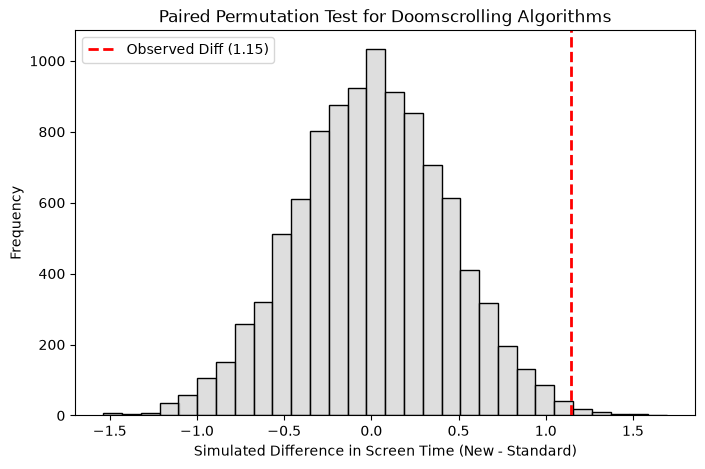

P-value for Paired Permutation Test (Doomscrolling Algorithms): 0.0078


In [8]:
# paired permutation test
def paired_permutation_test(df, col1, col2, n_permutations=10000):
    observed_difference = df[col2] - df[col1]
    observed_stat = observed_difference.mean()
    null_distribution = []
    for _ in range(n_permutations):
        permuted_difference = observed_difference.copy()
        flip = np.random.choice([True, False], size=len(permuted_difference))
        permuted_difference[flip] = -permuted_difference[flip]
        null_distribution.append(permuted_difference.mean())
    null_distribution = np.array(null_distribution)
    p_value = (np.abs(null_distribution) >= np.abs(observed_stat)).mean()
    return observed_stat, p_value, null_distribution

obs_diff, p_value, null_dist = paired_permutation_test(df_doomscrolling, 'standard_time', 'new_time', n_permutations=10000)

plt.figure(figsize=(8, 5))
sns.histplot(null_dist, bins=30, color='lightgray', edgecolor='black')
plt.axvline(obs_diff, color='red', linestyle='dashed', linewidth=2, label=f'Observed Diff ({obs_diff:.2f})')
plt.title('Paired Permutation Test for Doomscrolling Algorithms')
plt.xlabel('Simulated Difference in Screen Time (New - Standard)')
plt.ylabel('Frequency')
plt.legend()
plt.show()

print(f"P-value for Paired Permutation Test (Doomscrolling Algorithms): {p_value:.4f}")

Write a one-paragraph summary of the results for the doomscrolling algorithms. Include the observed difference, the p-value, and a conclusion on whether the new algorithm significantly increases screen time. Be sure to include what the hypothesis test is testing.

The results show that the new algorithm increased the average daily screen time from 118.43 minutes to 119.79 minutes, which is a difference of around 1.36 minutes per user. The hypothesis test is testing whether the new algorithm actually changes the average screen time or if the difference could just be due to random chance. Looking at the graph, most of the simulated differences are centered around zero, while our observed difference of 1.36 minutes is far to the right, outside where most of the simulated results fall. The p-value was 0.0008, which is much lower than 0.05, meaning the results are statistically significant. This gives us enough evidence to reject the null hypothesis and conclude that the new algorithm increases screen time. However, I think it is important to mention that even though the results are statistically significant, the increase is only about 1.36 minutes per day, which is not a very big difference for a social media app like Instagram or TikTok. So, while the new algorithm seems to be more effective at keeping users on the app, the company should consider whether this small increase is worth implementing it as it does not make much of a difference.